In [ ]:
# Import neccessary libraries
import itertools

import pandas as pd
import numpy as np

# For graph plot
import matplotlib.pyplot as plt
from matplotlib import cm
import seaborn as sns

# For feature scaling
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler, MaxAbsScaler

# For DLNM model
from statsmodels.gam.gam_cross_validation.cross_validators import KFold
import statsmodels.api as sm
from statsmodels.gam.smooth_basis import UnivariateBSplines, UnivariateCubicCyclicSplines
from statsmodels.gam.api import GLMGam, BSplines, CyclicCubicSplines
from statsmodels.gam.gam_cross_validation.gam_cross_validation import MultivariateGAMCVPath
from statsmodels.genmod.families.family import Tweedie
from statsmodels.genmod.families.links import log
from statsmodels.gam.smooth_basis import GenericSmoothers
from pydlnm.basis import CrossBasis
from pydlnm.prediction import crosspred
from pydlnm.utils import logknots
from dlnm import crossbasis, plot_crosspred, cb_pen


In [ ]:
# Function for constructing the CrossBasis matrix
def crossbasis_construct(dataframe, col_lst, max_lag, setting_lst): 
    # setting_lst include the values for the degree and degree of freedom (df) for both exposure and lag dimension in order
    
    # Initlialize the list to place cross basis matrices
    cb_list = []

    # Construct cross basis for each exposure variables
    for col in col_lst:
        knots_var = np.quantile(dataframe[col].dropna(), [0.1, 0.75, 0.9])
        lag_knots = logknots([0, max_lag], nk=setting_lst[3])

        tmp_cb = CrossBasis(dataframe[col].values, lag=max_lag, 
                                argvar={"fun": "bs", "degree": setting_lst[0], "df": setting_lst[1]}, 
                                arglag={"fun": "bs", "degree": setting_lst[2], "df": setting_lst[3]})
        cb_list.append(tmp_cb)

    X_exposure = np.concat(cb_list, axis=1)

    # Construct the DataFrame object for later model construction 
    model_data = np.concat([dataframe.to_numpy(), X_exposure], axis=1)
    model_data = pd.DataFrame(model_data)

    # Rename the columns of the mode_data DataFrame 
    exp_name_list = [f"{col}_basis_{i}" for col in col_lst for i in range(tmp_cb.shape[1])]
    model_data.columns = [n for n in dataframe.columns if n!="From"] + exp_name_list

    # Fill in 0 for the missing value(s)
    model_data[exp_name_list] = model_data[exp_name_list].fillna(0)

    # Return the variables that need to be used 
    return model_data, exp_name_list, cb_list

In [4]:
# Function for constructing the smoothers 
def smoothers_construct(dataframe, bs_dict, cs_dict):
    # bs_dict and cs_dict contains the name, degree and df for the spline function constructions needed 
    
    bs_list = []
    # Use B spline for 'time' and 'stringency index'
    for i in range(len(bs_dict["name"])):
        tmp_bs = UnivariateBSplines(dataframe[bs_dict["name"][i]], df=bs_dict["df"][i], degree=bs_dict["degree"][i], include_intercept=False, variable_name=bs_dict["name"][i])
        bs_list.append(tmp_bs)
    
    # Use Cubic Cyclic Spline for 'Week'
    cs = UnivariateCubicCyclicSplines(dataframe[cs_dict["name"]], df=cs_dict["df"], constraints="center", variable_name=cs_dict["name"])

    # Group the two spline functions together to form a single smoother variable
    sm_weights = bs_list + [cs]
    X_smooth = dataframe[bs_dict["name"]+[cs_dict["name"]]]
    smoothers = GenericSmoothers(X_smooth, sm_weights)

    # Return the smoother variable
    return smoothers

In [ ]:
# Function for constructing GAM model with Negative Binomial family 
def NB_GAM_model(dataframe, tar_var, exp_names, smoothers, a): 
    # Initializa the formula
    formula = f"{tar_var} ~ {exp_names} + pandemic_flag"

    # Build and fit the model
    NegativeBinomial_gam_model = GLMGam.from_formula(formula, data=dataframe, smoother=smoothers, alpha=a, family=sm.families.NegativeBinomial(alpha=2.0))
    result = NegativeBinomial_gam_model.fit()
    # result = NegativeBinomial_gam_model.fit_regularized(method="l1_slsqp", alpha=1.0)
        # no penalization for Negative Binomial

    # Return the model and the result 
    return NegativeBinomial_gam_model, result

In [6]:
# Function for 
def pred_cal(result, dataframe, cb_lst, mete_lst, i):
    n_cb_cols = cb_lst[i].shape[1]
    start_idx = 0
    end_idx = start_idx+n_cb_cols
    cb_coef = result.params.values[start_idx:end_idx]
    cb_vcov = result.cov_params().iloc[start_idx:end_idx, start_idx:end_idx]
    at = np.linspace(dataframe[mete_lst[i]].min(), dataframe[mete_lst[i]].max(), 100)
    cen = dataframe[mete_lst[i]].median()
    pred = crosspred(basis=cb_lst[i], coef=cb_coef, vcov=cb_vcov, model_link="log", at=at, cen=cen)
    
    print(f"{mete_lst[i]} RR range: {pred.allRRfit.min():.3f} to {pred.allRRfit.max():.3f}")

    return pred

In [7]:
# Function for plotting the 3D graph 
def graph_3Dplot(pred, exp):
    fig = plot_crosspred(pred, ptype="3d")

    ax = fig.gca()
    ax.set_title("3D Exposure-Lag-Response Association Surface", fontsize=14, fontweight='bold', pad=15)
    ax.set_xlabel(exp, fontsize=12, labelpad=10)
    ax.set_ylabel("Lag (Weeks)", fontsize=12, labelpad=10)
    ax.set_zlabel("Residual Risk (RR)", labelpad=10)
    ax.set_yticks(np.linspace(0, 4, pred.matRRfit.shape[1]))

    collections = ax.collections[0]
    vmin, vmax = collections.get_array().min(), collections.get_array().max()

    collections.set_clim(vmin, vmax)
    cbar = fig.colorbar(collections, ax=ax, shrink=0.6, pad=0.1)
    cbar.set_label("Relative Risk (RR)", rotation=270, labelpad=20)

    plt.tight_layout()
    plt.show()

In [8]:
# Function for plotting the exposure-response slice plot
def graph_expresponseplot(pred, exp):
    fig = plot_crosspred(pred, ptype="overall")
    cen = df[exp].median()

    ax = fig.gca()

    ax.axvline(x=cen, color='black', linestyle=':', linewidth=1.2, label=f'Centering Temp ({cen:.1f}°C)')
    ax.set_title('Overall Cumulative Exposure-Response Association', fontsize=14, pad=15)
    ax.set_xlabel(exp, fontsize=12)
    ax.legend(loc="best", frameon=True)

    plt.show()

In [9]:
# Function for plotting the lag-response slice plot
def graph_lagresponseplot(pred, target_var):
    fig = plot_crosspred(
        pred, 
        ptype="slices", 
        var=target_var
    )

    ax = fig.gca()

    ax.set_title(f"Lag-Response Curve at {target_var}", fontsize=14, fontweight='bold')
    ax.set_xlabel("Lag (Weeks)", fontsize=12)
    ax.set_ylabel("Relative Risk (RR)", fontsize=12)
    ax.axhline(1, color='gray', linestyle='--', alpha=0.7) # Add baseline at RR=1
    
    plt.show()

In [10]:
# Function for all the three plots at the same time 
def graph_plot(pred, exp, val):
    graph_3Dplot(pred, exp)
    graph_expresponseplot(pred, exp)
    graph_lagresponseplot(pred, val)

In [86]:
def alpha_tune(dataframe, tar_var, exp_names, smoothers, crit, meth):
    model, result = NB_GAM_model(dataframe, tar_var, exp_names, smoothers, [100, 500, 500])
    best_a = model.select_penweight(criterion=crit, method=meth, start_params=np.array([10, 10, 10]))
    return best_a

In [11]:
# Find the optimal alpha value with the AIC value of the model performance 
def alpha_byAIC(dataframe, tar_var, exp_names, smoothers, alpha):
    best_a = 0
    best_aic = np.inf

    for a1, a2, a3 in itertools.product(alpha, alpha, alpha):
        model, result = NB_GAM_model(dataframe, tar_var, exp_names, smoothers, [a1, a2, a3])
        print(f"alpha {[a1, a2, a3]} with AIC value {result.aic}")
        if result.aic < best_aic:
            best_aic = result.aic
            best_a = [a1, a2, a3]

    return best_a

In [12]:
# Find the optimal alpha value with the GCV value
def alpha_byGCV(dataframe, tar_var, exp_names, smoothers):
    model, result = NB_GAM_model(dataframe, tar_var, exp_names, smoothers, [100, 500, 500])
    best_a = model.select_penweight(criterion="gcv")
    return best_a[0]

In [13]:
# Find the degree and degrees of freedom for the CrossBasis
def cb_setting_performance(dataframe, exp_col, setting_options):
    best_setting_idx = 0
    performance = []
    for setting in setting_options:
        model_data, exp_name_list, cb_list = crossbasis_construct(dataframe, exp_col, 4, setting)
        smoothers = smoothers_construct(model_data, {"name": ["time", "ContainmentHealthIndex_Average"], "degree": [3, 3], "df": [6, 4]}, {"name": "Week", "df": 4})
        initial_alpha = [500.0, 500.0, 500.0]
        model, result = NB_GAM_model(model_data, "H1",  " + ".join(exp_name_list), smoothers, initial_alpha)
        print(f"AIC value for the settings {set}: {result.aic}")
        performance.append([result.aic, result.deviance, result.null_deviance, result.df_resid, result.df_model])

    for i in range(1, len(performance)):
        if performance[i][0] < performance[best_setting_idx][0]:
            best_setting_idx = i

    return setting_options[best_setting_idx]


In [14]:
# Function for feature scaling (uses standardization)
def feature_scaling():
    df[mete_col] = StandardScaler().fit_transform(df[mete_col])
    df["Year"] = df["Year"] - df["Year"].mean()
  

---

In [ ]:
# Import data and basic settings
df = pd.read_csv("data.csv")

df.columns = ["Year", "Week", "From", "temprange", "temp", "RH", "SR", "AP", "DPT", "WS", "UV", "H1", "H3", "B", "AandB"]

mete_col = ["temprange", "temp", "RH", "SR", "AP", "DPT", "WS", "UV"]
flu_col = ["H1", "H3", "B", "AandB"]

# Drop unnecessary columns
df.drop(columns=["From"], inplace=True)

# Add a new column <"time"> to df 
df["time"] = np.arange(1, len(df)+1)

In [20]:
# overview for df 
df.head()

,Year,Week,temprange,temp,RH,SR,AP,DPT,WS,UV,H1,H3,B,AandB,ContainmentHealthIndex_Average,pandemic_flag,time
0,2002,36,14.3,28.15,76.5,19.66,1008.20,23.20,7.35,4.0,1,12,3.0,19,0.0,0.0,1
1,2002,37,13.6,26.70,85.0,9.35,1006.30,23.80,10.50,3.0,0,6,4.0,15,0.0,0.0,2
2,2002,38,11.2,26.40,83.0,16.75,1011.35,23.20,13.45,4.0,0,4,4.0,13,0.0,0.0,3
3,2002,39,10.0,25.90,85.0,10.93,1012.90,23.25,13.25,3.0,0,2,6.0,10,0.0,0.0,4
4,2002,40,10.6,25.95,82.0,11.56,1012.80,22.40,10.05,3.0,0,6,2.0,8,0.0,0.0,5


In [ ]:
# Feature scaling and selection
np.random.seed(42)

feature_scaling()


'\nfeature_selection_MI(df, mete_col, "H1")\nmete_col = feature_selection_MRMR(df, mete_col, "H1")\n'

In [22]:
# Grid for the CrossBasis settings 
setting_options = [
    [2, 5, 3, 5], 
    [2, 4, 3, 5], 
    [2, 3, 3, 5], 
    [2, 5, 2, 4],
    [2, 4, 2, 4]
]

# Find the best Cross Basis settings
best_cb_setting = cb_setting_performance(df, mete_col, setting_options)
print(f"The best CrossBasis settings [degree for exposure dimension, df for exposure dimension, degree for lag dimension, df for lag simension]: \n{best_cb_setting}")

AIC value for the settings <class 'set'>: 10278.559362308886
AIC value for the settings <class 'set'>: 10394.819263225383
AIC value for the settings <class 'set'>: 10331.723796135613
AIC value for the settings <class 'set'>: 10194.510265712264
AIC value for the settings <class 'set'>: 10227.205991840094
The best CrossBasis settings [degree for exposure dimension, df for exposure dimension, degree for lag dimension, df for lag simension]: 
[2, 5, 2, 4]


In [23]:
model_data, exp_name_list, cb_list = crossbasis_construct(df, mete_col, 4, best_cb_setting)

display(model_data.head())

,Year,Week,temprange,temp,RH,SR,AP,DPT,WS,UV,...,UV_basis_10,UV_basis_11,UV_basis_12,UV_basis_13,UV_basis_14,UV_basis_15,UV_basis_16,UV_basis_17,UV_basis_18,UV_basis_19
0,-12.172386,36.0,-0.159389,0.952562,-0.263359,1.074896,-0.768413,0.666793,-1.504003,0.882471,...,0.00,0.000,0.0,0.000,0.000,0.00,0.0,0.0,0.0,0.0
1,-12.172386,37.0,-0.357210,0.662780,0.737677,-0.882043,-1.081663,0.767450,0.235168,0.086233,...,0.00,0.000,0.0,0.000,0.000,0.00,0.0,0.0,0.0,0.0
2,-12.172386,38.0,-1.035453,0.602825,0.502139,0.522550,-0.249079,0.666793,1.863914,0.882471,...,0.00,0.000,0.0,0.000,0.000,0.00,0.0,0.0,0.0,0.0
3,-12.172386,39.0,-1.374575,0.502901,0.737677,-0.582144,0.006467,0.675181,1.753491,0.086233,...,0.00,0.000,0.0,0.000,0.000,0.00,0.0,0.0,0.0,0.0
4,-12.172386,40.0,-1.205014,0.512893,0.384370,-0.462563,-0.010020,0.532584,-0.013285,0.086233,...,0.75,0.875,0.0,0.125,0.125,0.25,0.0,0.0,0.0,0.0


In [24]:
model_data.describe()

,Year,Week,temprange,temp,RH,SR,AP,DPT,WS,UV,...,UV_basis_10,UV_basis_11,UV_basis_12,UV_basis_13,UV_basis_14,UV_basis_15,UV_basis_16,UV_basis_17,UV_basis_18,UV_basis_19
count,1.253000e+03,1253.000000,1.253000e+03,1.253000e+03,1.253000e+03,1.253000e+03,1.253000e+03,1.253000e+03,1.253000e+03,1.253000e+03,...,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000
mean,-7.258537e-14,26.605746,-4.423171e-16,-4.536586e-17,-2.438415e-16,-1.360976e-16,-4.849894e-15,1.134146e-17,-1.474390e-16,-2.551829e-17,...,0.370399,0.370756,0.130666,0.130790,0.130890,0.130671,0.030261,0.030261,0.030261,0.030172
std,6.945058e+00,15.077257,1.000399e+00,1.000399e+00,1.000399e+00,1.000399e+00,1.000399e+00,1.000399e+00,1.000399e+00,1.000399e+00,...,0.289627,0.327437,0.205850,0.185083,0.185063,0.205498,0.097403,0.085041,0.085041,0.097380
min,-1.217239e+01,1.000000,-3.098443e+00,-2.894536e+00,-4.208616e+00,-2.273350e+00,-2.656154e+00,-3.242039e+00,-2.497814e+00,-1.983988e+00,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,-6.172386e+00,14.000000,-7.528518e-01,-8.560741e-01,-4.988964e-01,-7.719536e-01,-8.013869e-01,-7.256234e-01,-7.034321e-01,-7.100059e-01,...,0.062500,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,-1.723863e-01,27.000000,-2.441694e-01,2.031269e-01,1.488324e-01,4.612698e-02,-1.001972e-02,2.138384e-01,-4.089107e-02,8.623270e-02,...,0.343750,0.416667,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,5.827614e+00,40.000000,6.036347e-01,9.225841e-01,7.376768e-01,6.990729e-01,7.895909e-01,9.352110e-01,6.216500e-01,8.824713e-01,...,0.625000,0.625000,0.250000,0.215278,0.215278,0.250000,0.000000,0.000000,0.000000,0.000000
max,1.182761e+01,53.000000,3.627469e+00,1.662026e+00,1.797597e+00,2.365604e+00,2.446516e+00,1.270733e+00,4.265626e+00,3.271187e+00,...,0.976562,1.000000,0.694444,0.694444,0.694444,0.694444,1.111111,0.902778,0.791667,1.027778


In [77]:
smoothers = smoothers_construct(model_data, {"name": ["time", "ContainmentHealthIndex_Average"], "degree": [3, 3], "df": [6, 4]}, {"name": "Week", "df": 4})


In [26]:
alpha_choice = [1.0, 10.0, 50.0, 100.0]
best_a_aic = alpha_byAIC(model_data, "H1", " + ".join(exp_name_list), smoothers, alpha_choice)

print(f"alpha {best_a_aic} is the best tested with AIC")

alpha [1.0, 1.0, 1.0] with AIC value 10198.293328300351
alpha [1.0, 1.0, 10.0] with AIC value 10198.094957893998
alpha [1.0, 1.0, 50.0] with AIC value 10197.263170686445
alpha [1.0, 1.0, 100.0] with AIC value 10196.318084762976
alpha [1.0, 10.0, 1.0] with AIC value 10198.191531776603
alpha [1.0, 10.0, 10.0] with AIC value 10197.993146931287
alpha [1.0, 10.0, 50.0] with AIC value 10197.161910354302
alpha [1.0, 10.0, 100.0] with AIC value 10196.218827557952
alpha [1.0, 50.0, 1.0] with AIC value 10197.814938811725
alpha [1.0, 50.0, 10.0] with AIC value 10197.616744038032
alpha [1.0, 50.0, 50.0] with AIC value 10196.78914087665
alpha [1.0, 50.0, 100.0] with AIC value 10182.411678502902
alpha [1.0, 100.0, 1.0] with AIC value 10197.50724816785
alpha [1.0, 100.0, 10.0] with AIC value 10197.309890409528
alpha [1.0, 100.0, 50.0] with AIC value 10182.419730160267
alpha [1.0, 100.0, 100.0] with AIC value 10181.858663774887
alpha [10.0, 1.0, 1.0] with AIC value 10198.294084723702
alpha [10.0, 1.0,

In [ ]:
best_a_aic = alpha_tune(model_data, "H1", " + ".join(exp_name_list), "aic", "minimize")

In [27]:
best_a_gcv = alpha_byGCV(model_data, "H1", " + ".join(exp_name_list), smoothers)

print(f"alpha {best_a_gcv} is the best tested with GCV")


alpha [5.72770329e+00 3.67919285e+02 1.78288302e-03] is the best tested with GCV


In [ ]:
best_a_gcv = alpha_tune(model_data, "H1", " + ".join(exp_name_list), "gcv", "minimize")

print(f"alpha {best_a_gcv[0]} is the best tested with GCV")


In [28]:
model, result = NB_GAM_model(model_data, "H1", " + ".join(exp_name_list), smoothers, best_a_aic)
print(result.summary())


                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1253
Model:                         GLMGam   Df Residuals:                  1090.36
Model Family:        NegativeBinomial   Df Model:                       161.64
Link Function:                    Log   Scale:                          1.0000
Method:                         PIRLS   Log-Likelihood:                -4928.3
Date:                Sat, 14 Nov 2026   Deviance:                       3699.6
Time:                        17:36:05   Pearson chi2:                 6.62e+04
No. Iterations:                  1000   Pseudo R-squ. (CS):             0.9980
Covariance Type:            nonrobust                                         
                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Interc

In [29]:
for s in smoothers.smoothers:
    if getattr(s, "der_basis", None) is None:
        s.der_basis = np.zeros_like(s.basis)
    if getattr(s, "der2_basis", None) is None:
        s.der2_basis = np.zeros_like(s.basis)

best_a_kfold = model.select_penweight_kfold()
print(f"alpha {best_a_kfold[0]} is the best tested with kfold")

alpha (np.float64(79432.82347242805), np.float64(1.0), np.float64(10000000.0)) is the best tested with kfold


In [84]:
print(best_a_reml[1])

  message: Desired error not necessarily achieved due to precision loss.
  success: False
   status: 2
      fun: 9904.681479570323
        x: [ 0.000e+00  0.000e+00  0.000e+00]
      nit: 0
      jac: [ 1.453e+10  3.688e+10  4.116e+10]
 hess_inv: [[1 0 0]
            [0 1 0]
            [0 0 1]]
     nfev: 108
     njev: 24


In [ ]:
best_a_bic = alpha_tune(model_data, "H1", " + ".join(exp_name_list), smoothers, "bic", "nm")
print(best_a_bic)


In [ ]:
# Model diagnostics / Goodness-of-fit
print(f"AIC: {result.aic}")
print(f"BIC: {result.bic}")
print(f"Deviance: {result.deviance}")
print(f"Pearson Chi2: {result.pearson_chi2}")
print(f"Scale/Dispersion: {result.scale}")
print(f"Effective degree of freedom: \n{result.edf}")
print(f"Total EDF: {result.edf.sum()}")

AIC: 10181.858663774887
BIC: 11016.74596523325
Deviance: 3699.620614747045
Pearson Chi2: 66151.40971332797
Scale/Dispersion: 1.0
Effective degree of freedom: 
[ 1.66153588  1.51199704  0.14823256 -1.33468183  0.75574897  2.48320349
 -0.15006783 -2.50421899  1.19943764  0.48083996  0.82517458 -0.32853275
  0.8474104   1.12412462  1.89821168 -0.19061887  0.89991467  0.63658179
  1.0664488   0.68100747  0.94482229  1.92883029  1.20834125  1.14689001
  1.54524291  1.70789487  2.91066498  1.20587721  0.59479198  0.435028
  0.4777646  -0.10300748  0.16576336  1.84539271  1.31985756  0.55074725
  0.7120564   1.22728619  1.714087    0.95221697  1.13537149  0.95565567
  0.18388613  2.05897932  0.91652987  1.07514032  1.43753822  2.51943349
  1.15595191  2.29875631  2.03662242  0.64825298  0.82557238  1.38816601
  1.50867839  0.33497528  0.92492356  0.81270917  0.98422556  0.88258734
  0.9289381   0.6497793   0.09392978  1.08963039  1.46965437  0.81745952
  0.28229351  1.24760865  1.43421137  1.

In [37]:
# Find the index of the highest fitted value
extreme_idx = result.fittedvalues.idxmax()

print(f"Index of extreme row: {extreme_idx}")
print(f"Actual Outcome Value: {model_data.loc[extreme_idx, "H1"]}")
print(f"Fitted Value: {result.fittedvalues[extreme_idx]}")
print(model_data.loc[extreme_idx])

Index of extreme row: 805
Actual Outcome Value: 270.0
Fitted Value: 6788.1627937782005
Year           3.827614
Week           6.000000
temprange      2.610104
temp          -2.255019
RH            -2.677620
                 ...   
UV_basis_15    0.000000
UV_basis_16    0.000000
UV_basis_17    0.000000
UV_basis_18    0.000000
UV_basis_19    0.000000
Name: 805, Length: 177, dtype: float64


In [31]:
model, result = NB_GAM_model(model_data, "H1", " + ".join(exp_name_list), smoothers, best_a_aic)


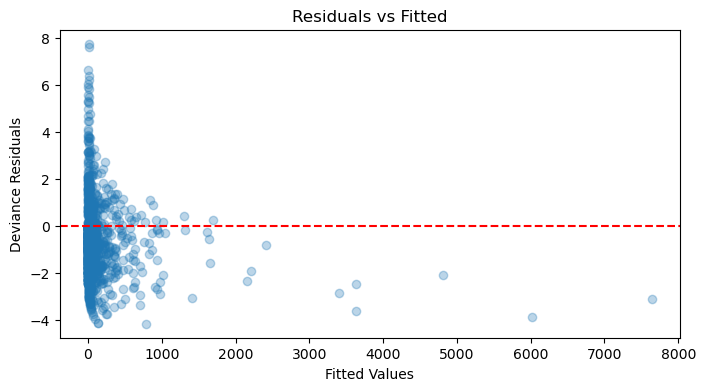

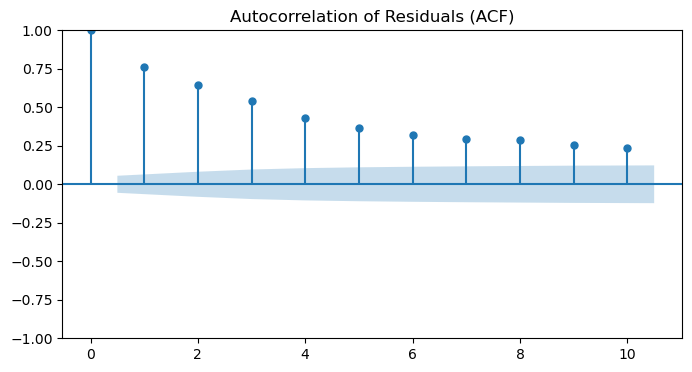

In [ ]:
# Residual diagnostics

# Extract deviance residuals
residuals = result.resid_deviance

# 1. Residuals vs. Fitted Values Plot (checks for systematic bias)
plt.figure(figsize=(8, 4))
plt.scatter(result.fittedvalues, residuals, alpha=0.3)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Fitted Values")
plt.ylabel("Deviance Residuals")
plt.title("Residuals vs Fitted")
plt.show()

# 2. Autocorrelation Check (ACF) - Vital for time series!
# Time-series data often has uncaptured temporal patterns; residuals should look like white noise.
fig, ax = plt.subplots(figsize=(8, 4))
sm.graphics.tsa.plot_acf(residuals, lags=10, ax=ax)
plt.title("Autocorrelation of Residuals (ACF)")
plt.show()

In [33]:
model, result = NB_GAM_model(model_data, "H1", " + ".join(exp_name_list), smoothers, best_a_gcv)


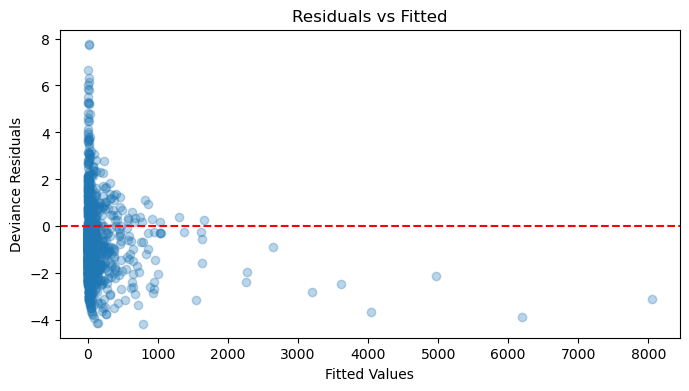

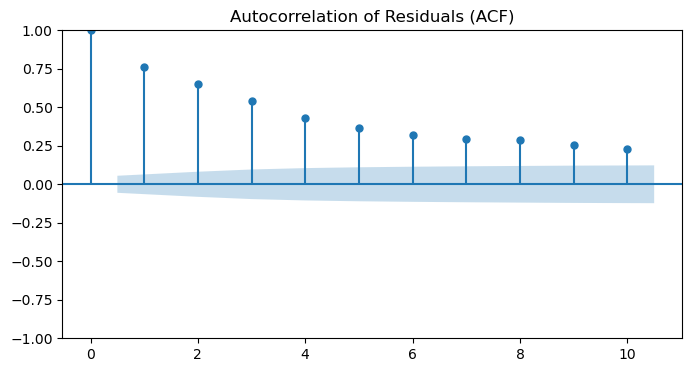

In [ ]:
# Residual diagnostics

# Extract deviance residuals
residuals = result.resid_deviance

# 1. Residuals vs. Fitted Values Plot (checks for systematic bias)
plt.figure(figsize=(8, 4))
plt.scatter(result.fittedvalues, residuals, alpha=0.3)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Fitted Values")
plt.ylabel("Deviance Residuals")
plt.title("Residuals vs Fitted")
plt.show()

# 2. Autocorrelation Check (ACF) - Vital for time series!
# Time-series data often has uncaptured temporal patterns; residuals should look like white noise.
fig, ax = plt.subplots(figsize=(8, 4))
sm.graphics.tsa.plot_acf(residuals, lags=10, ax=ax)
plt.title("Autocorrelation of Residuals (ACF)")
plt.show()

In [35]:
model, result = NB_GAM_model(model_data, "H1", " + ".join(exp_name_list), smoothers, best_a_kfold[0])


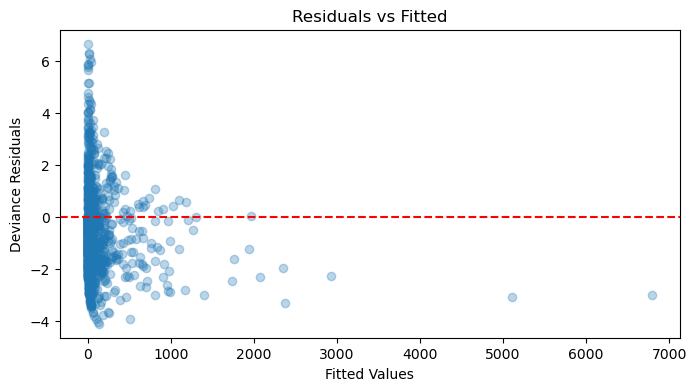

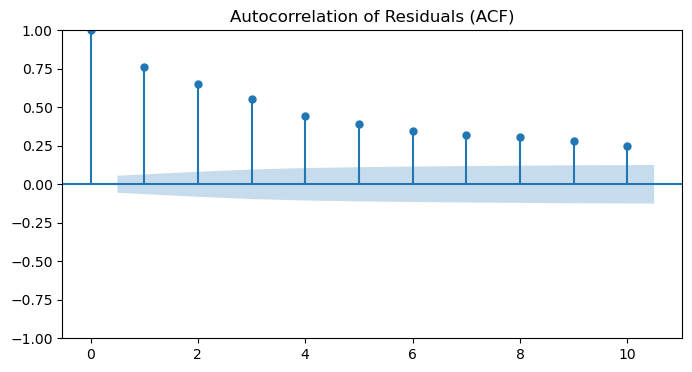

In [ ]:
# Residual diagnostics

# Extract deviance residuals
residuals = result.resid_deviance

# 1. Residuals vs. Fitted Values Plot (checks for systematic bias)
plt.figure(figsize=(8, 4))
plt.scatter(result.fittedvalues, residuals, alpha=0.3)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Fitted Values")
plt.ylabel("Deviance Residuals")
plt.title("Residuals vs Fitted")
plt.show()

# 2. Autocorrelation Check (ACF) - Vital for time series!
# Time-series data often has uncaptured temporal patterns; residuals should look like white noise.
fig, ax = plt.subplots(figsize=(8, 4))
sm.graphics.tsa.plot_acf(residuals, lags=10, ax=ax)
plt.title("Autocorrelation of Residuals (ACF)")
plt.show()

temprange RR range: 0.002 to 2.502


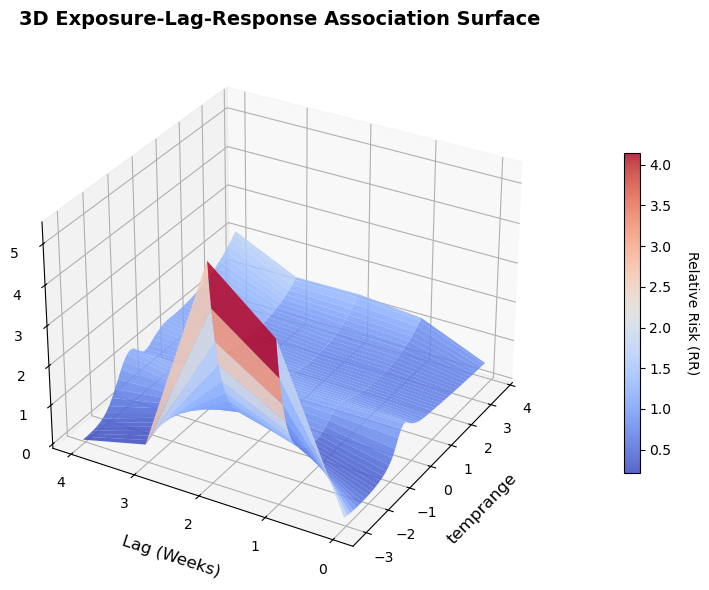

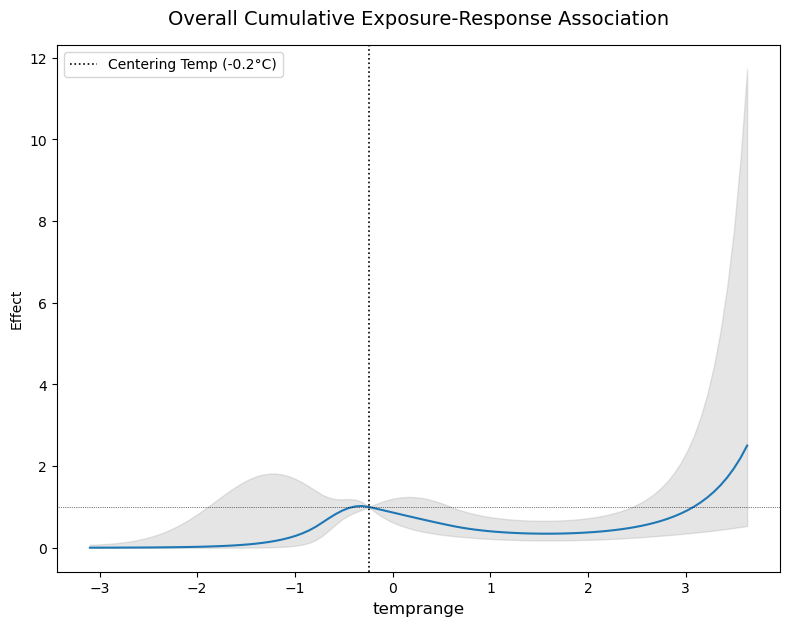

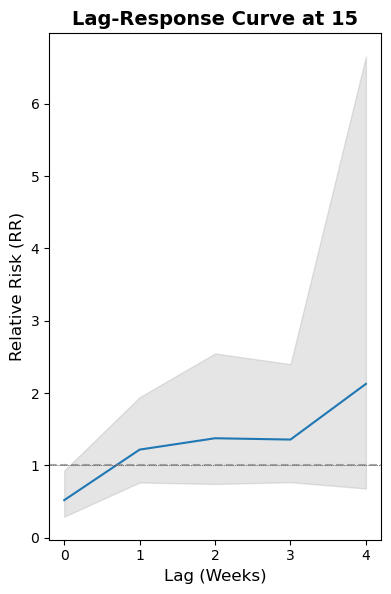

temp RR range: 0.003 to 2.714


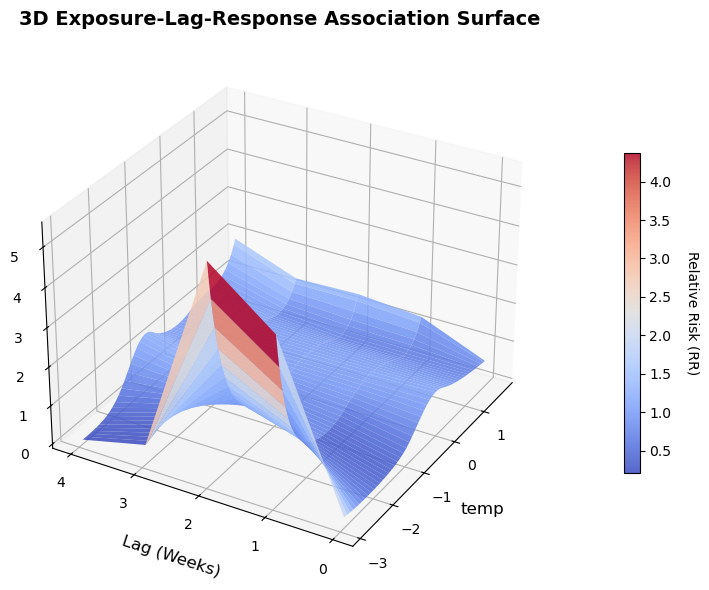

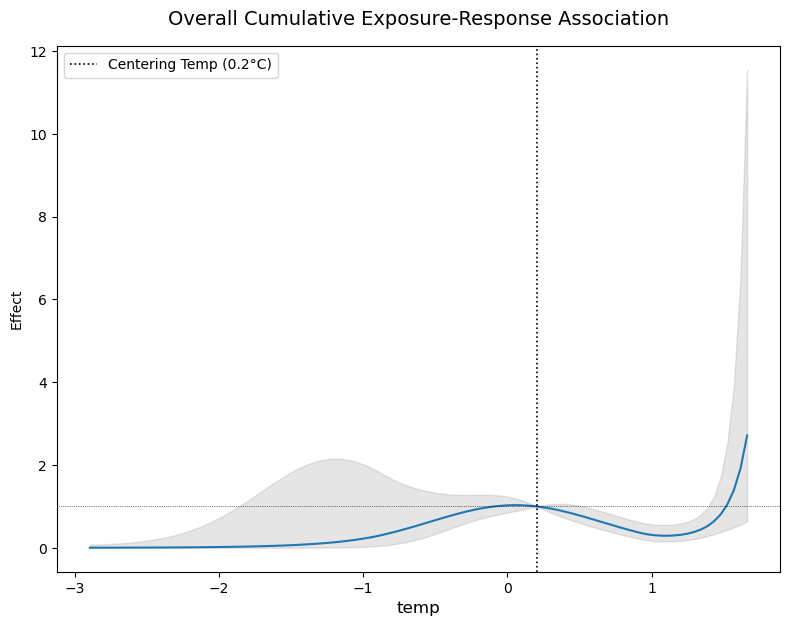

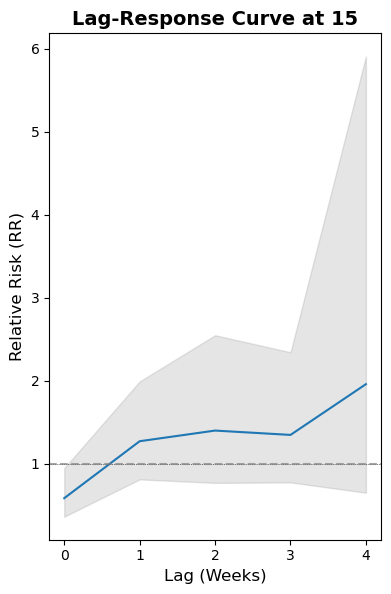

RH RR range: 0.003 to 2.644


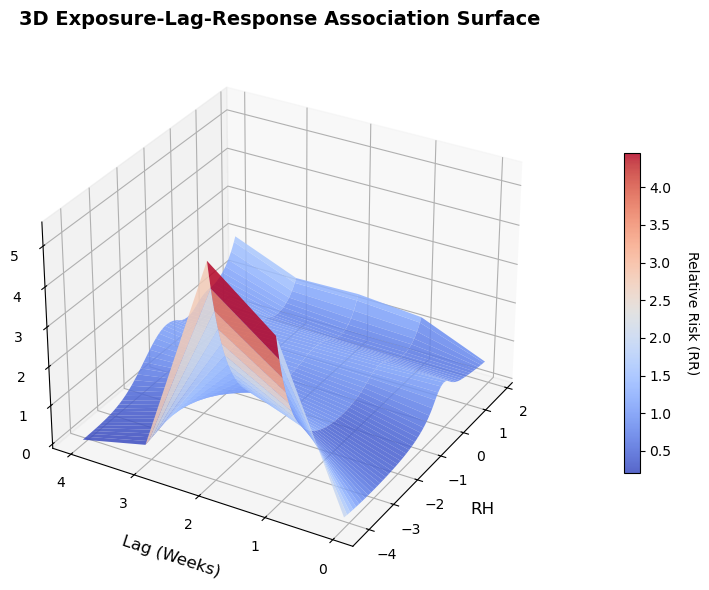

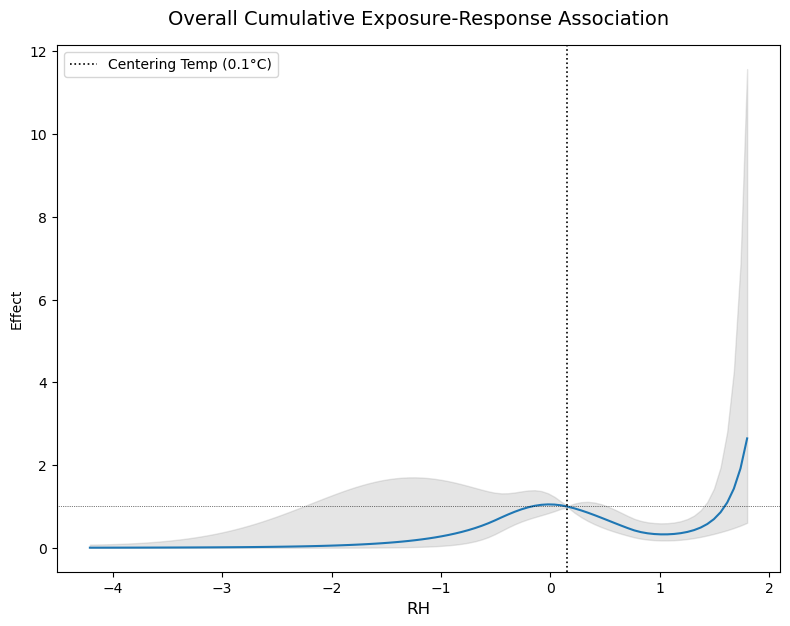

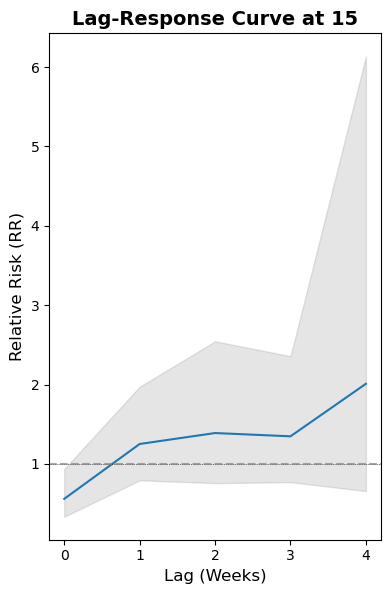

SR RR range: 0.003 to 2.675


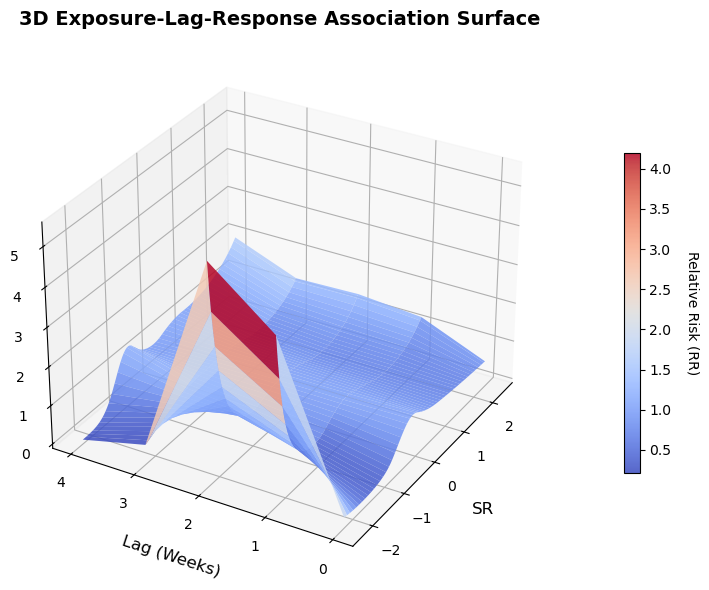

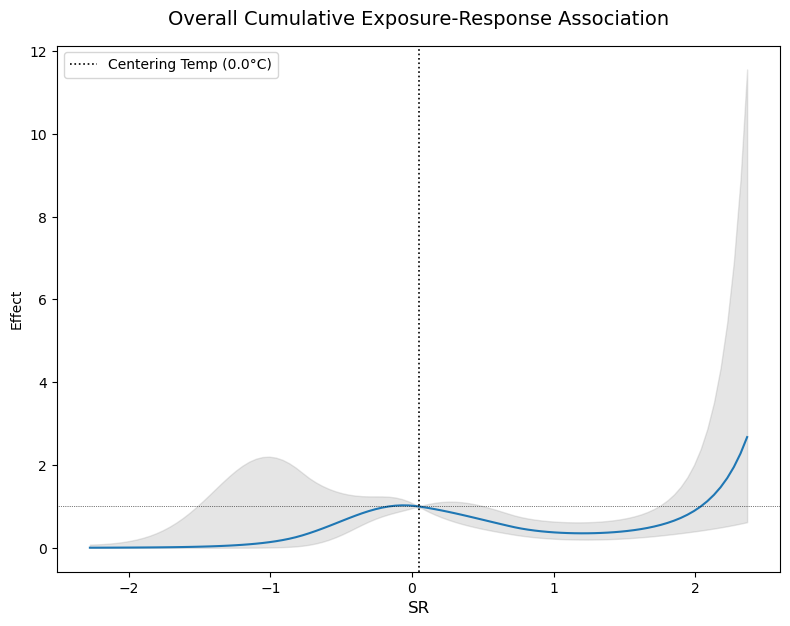

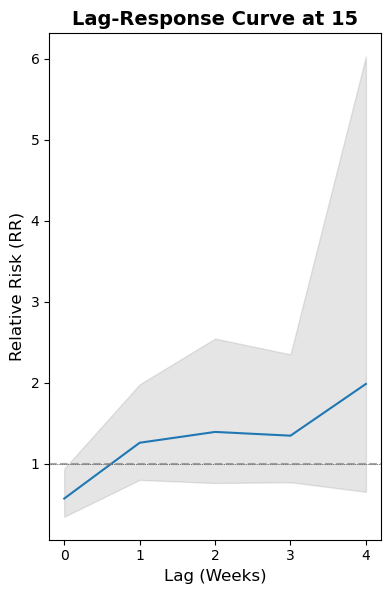

AP RR range: 0.002 to 2.618


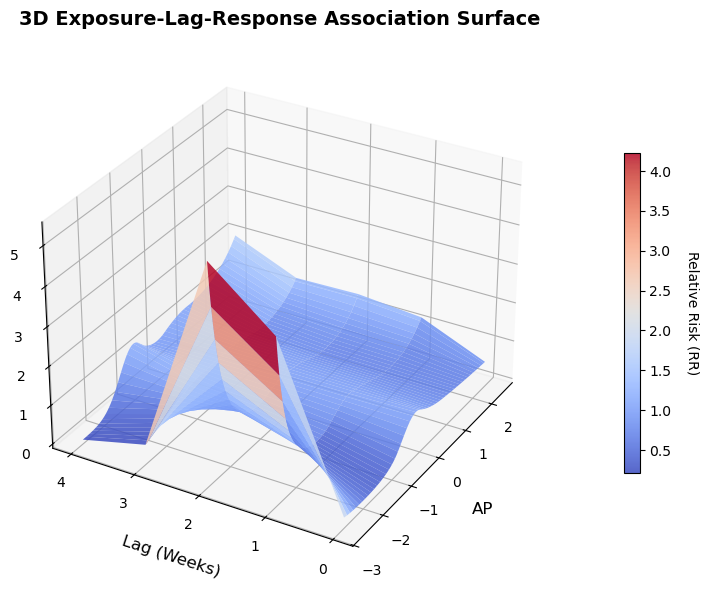

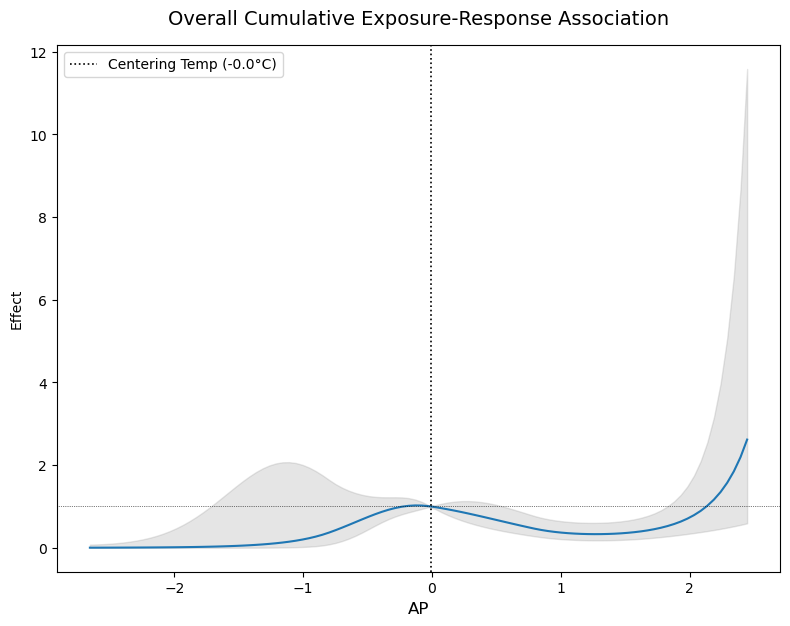

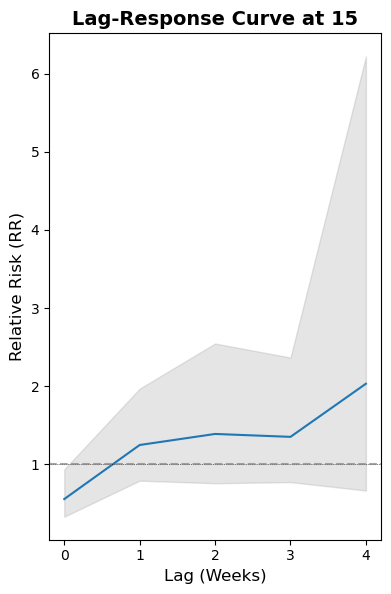

DPT RR range: 0.003 to 2.685


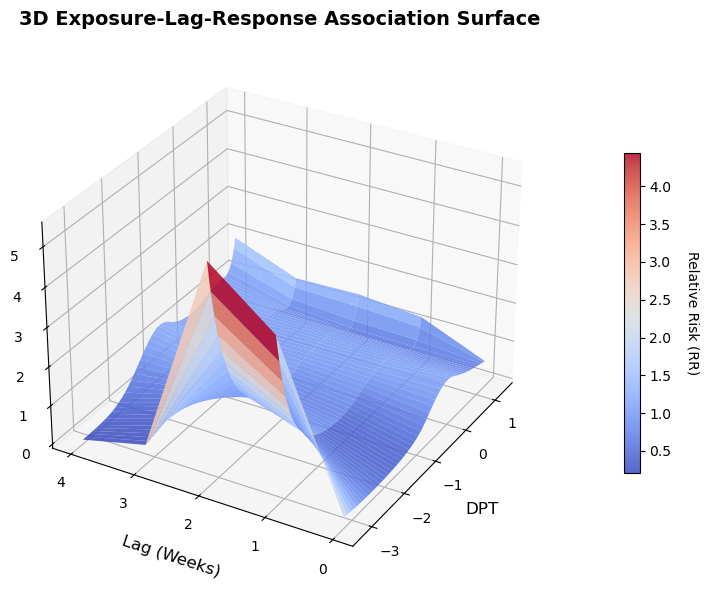

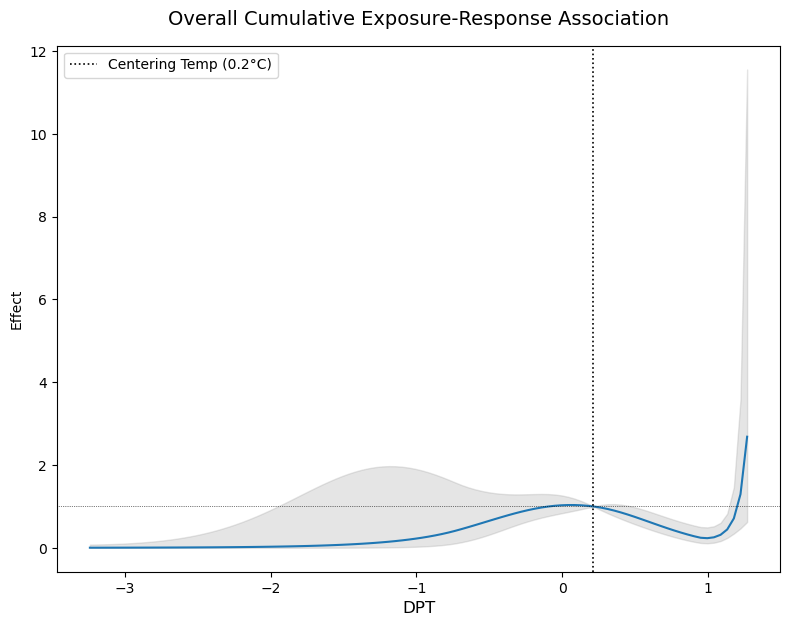

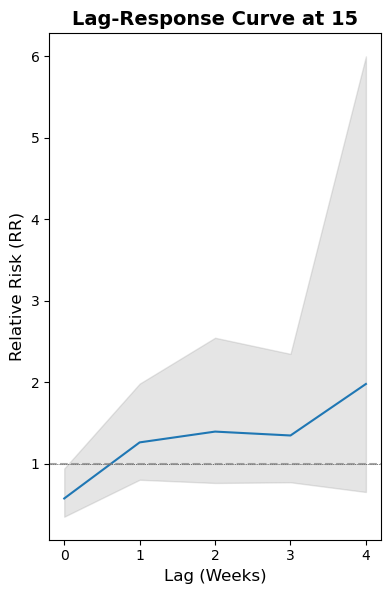

WS RR range: 0.002 to 2.620


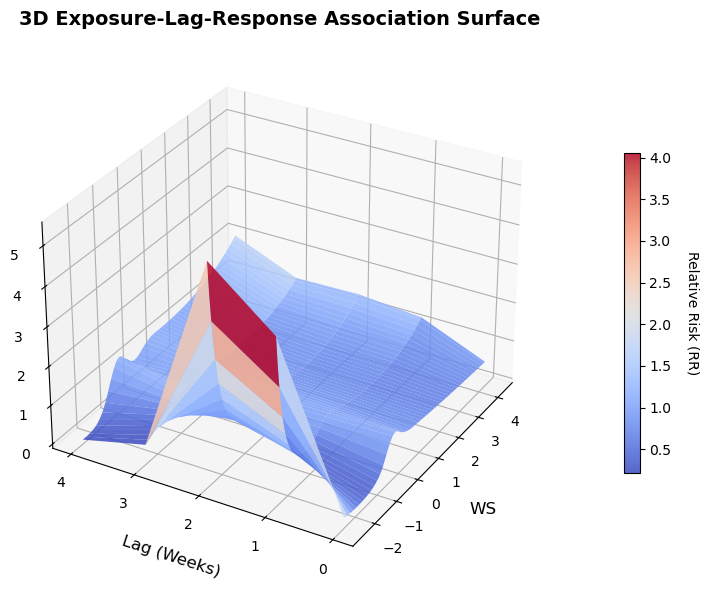

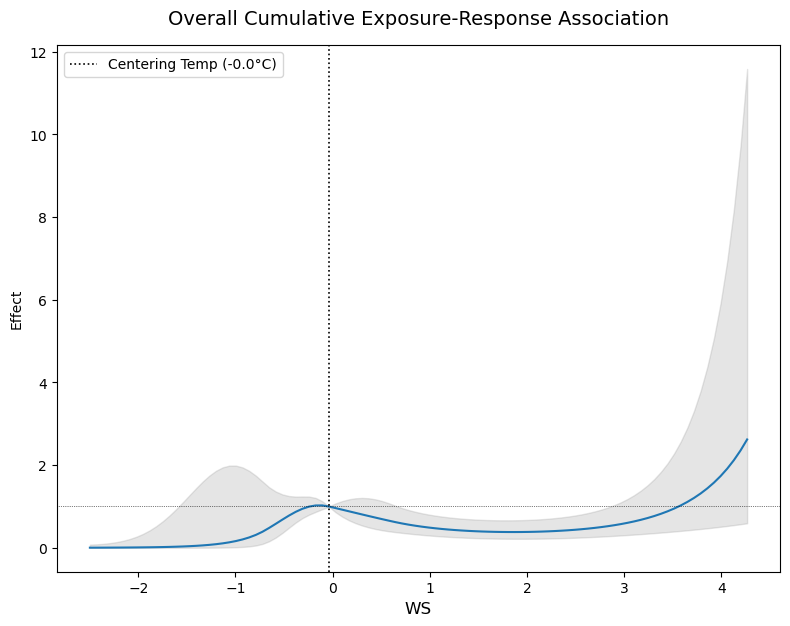

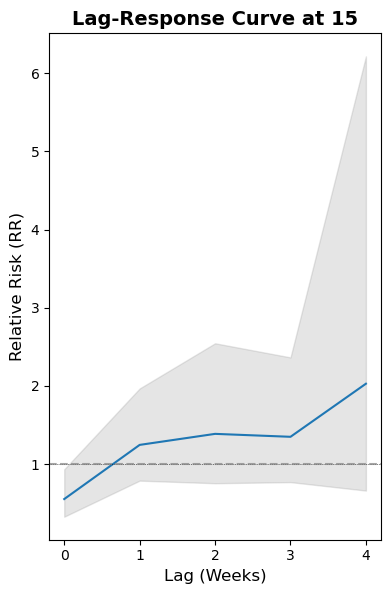

UV RR range: 0.002 to 2.620


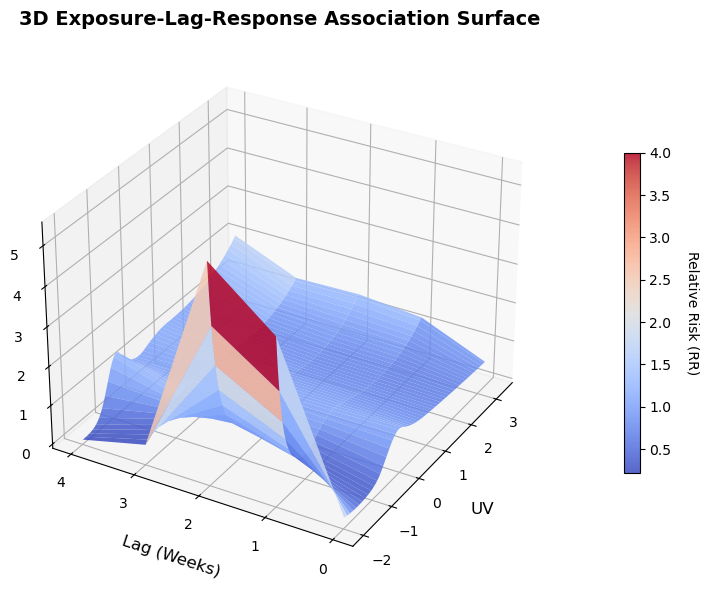

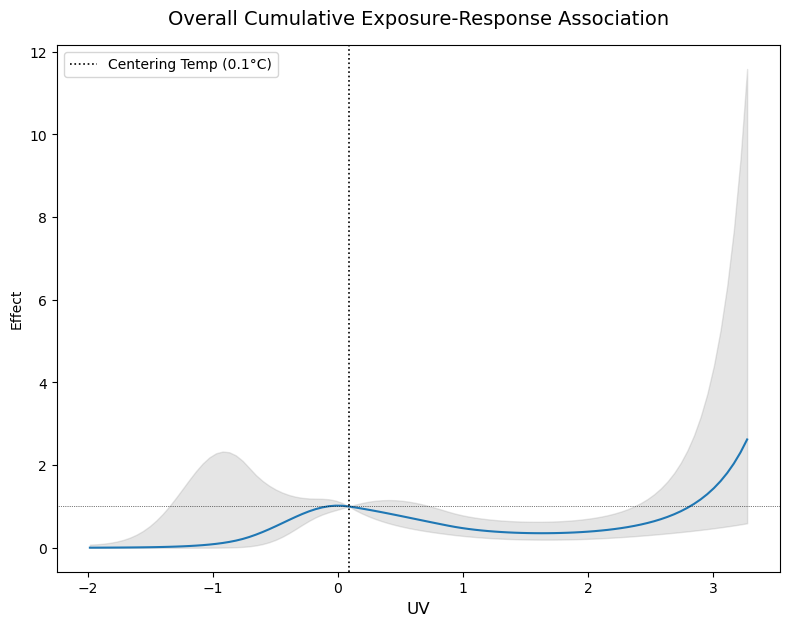

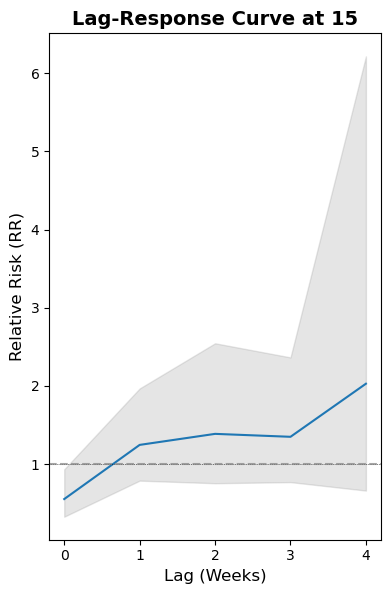

In [38]:
# Graph plots
for i in range(len(mete_col)):
    pred = pred_cal(result, model_data, cb_list, mete_col, i)
    graph_plot(pred, mete_col[i], 15)

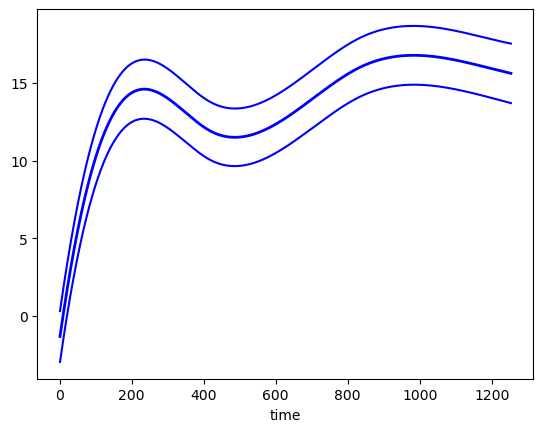

In [39]:
result.plot_partial(0)
plt.show()